# Semana 2 — GWO: Implementação, Validação e Sintonia com Optuna

**Aluno:** Rochel Andrey dos Santos Costa
**Disciplina:** Sistemas Inteligentes
**Data:** 26/10/2026

## Estrutura
1. Setup e upload das instâncias
2. Implementação canônica do GWO (do zero)
3. Funções de benchmark (Rastrigin, Rosenbrock, Ackley)
4. Validação: 30 execuções independentes + gráfico de convergência
5. FlowShopEngine (código do professor)
6. Adaptação do GWO ao FlowShop (chaves contínuas → permutação)
7. Sintonia de hiperparâmetros com Optuna
8. Tabela comparativa + gráficos do Optuna

In [ ]:
!pip install optuna -q

import os, zipfile, time, json
import numpy as np
import matplotlib.pyplot as plt
import optuna
from tqdm.auto import tqdm
from google.colab import files

# Upload do zip com as instâncias
print("Selecione o arquivo .zip com as instâncias:")
uploaded = files.upload()

# Extrai todos os zips enviados
for fname in uploaded.keys():
    if fname.endswith('.zip'):
        with zipfile.ZipFile(fname, 'r') as z:
            z.extractall('instancias')
        print(f"[OK] {fname} extraído.")

# Lista as instâncias disponíveis
for root, _, arquivos in os.walk('instancias'):
    for a in arquivos:
        print(os.path.join(root, a))

Selecione o arquivo .zip com as instâncias:


instancias/DPFSP_DD/Large/Ta033_7.txt
instancias/DPFSP_DD/Large/Ta071_6.txt
instancias/DPFSP_DD/Large/Ta108_4.txt
instancias/DPFSP_DD/Large/Ta093_6.txt
instancias/DPFSP_DD/Large/Ta007_4.txt
instancias/DPFSP_DD/Large/Ta085_5.txt
instancias/DPFSP_DD/Large/Ta003_7.txt
instancias/DPFSP_DD/Large/Ta072_3.txt
instancias/DPFSP_DD/Large/Ta012_7.txt
instancias/DPFSP_DD/Large/Ta004_4.txt
instancias/DPFSP_DD/Large/Ta021_6.txt
instancias/DPFSP_DD/Large/Ta092_3.txt
instancias/DPFSP_DD/Large/Ta079_7.txt
instancias/DPFSP_DD/Large/Ta036_6.txt
instancias/DPFSP_DD/Large/Ta072_6.txt
instancias/DPFSP_DD/Large/Ta052_6.txt
instancias/DPFSP_DD/Large/Ta087_7.txt
instancias/DPFSP_DD/Large/Ta083_6.txt
instancias/DPFSP_DD/Large/Ta083_7.txt
instancias/DPFSP_DD/Large/Ta103_4.txt
instancias/DPFSP_DD/Large/Ta098_5.txt
instancias/DPFSP_DD/Large/Ta050_6.txt
instancias/DPFSP_DD/Large/Ta104_2.txt
instancias/DPFSP_DD/Large/Ta047_3.txt
instancias/DPFSP_DD/Large/Ta036_3.txt
instancias/DPFSP_DD/Large/Ta056_7.txt
instancias/D

## 2. Implementação Canônica do GWO

Baseada em **Mirjalili, Mirjalili & Lewis (2014)** — *Grey Wolf Optimizer*, Advances in Engineering Software.

**Decisões de projeto:**
- Cada lobo é um vetor contínuo em `[lb, ub]^D`.
- Hierarquia: `α` (melhor), `β` (2º), `δ` (3º).
- Coeficiente `a` decai linearmente de 2 → 0.
- O solver é **agnóstico ao problema** (recebe `obj_func`).

In [ ]:
# ============================================================
# SEÇÃO 2: GWO canônico (implementado do zero)
# ============================================================
class GWO:
    """
    Grey Wolf Optimizer (Mirjalili et al., 2014).

    Parâmetros
    ----------
    obj_func : callable
        Função objetivo a MINIMIZAR: f(x) -> float
    dim : int
        Dimensionalidade do espaço de busca.
    lb, ub : array-like
        Limites inferior e superior de cada dimensão.
    n_wolves : int
        Tamanho da população.
    max_iter : int
        Número máximo de iterações.
    seed : int or None
        Semente para reprodutibilidade.
    a_decay : {"linear", "exponential", "sqrt"}
        Estratégia de decaimento do coeficiente `a` (2 → 0).
        - "linear"      : a = 2 - 2·(t/T)          (canônico, Mirjalili 2014)
        - "exponential" : a = 2·(1 - (t/T)²)       (decaimento mais rápido)
        - "sqrt"        : a = 2·sqrt(1 - t/T)      (decaimento mais lento)
    """

    def __init__(self, obj_func, dim, lb, ub, n_wolves=30, max_iter=500,
                 seed=None, a_decay="linear"):
        self.obj_func = obj_func
        self.dim = dim
        self.lb = np.full(dim, lb) if np.isscalar(lb) else np.asarray(lb, dtype=float)
        self.ub = np.full(dim, ub) if np.isscalar(ub) else np.asarray(ub, dtype=float)
        self.n_wolves = n_wolves
        self.max_iter = max_iter
        self.seed = seed
        self.a_decay = a_decay
        if a_decay not in ("linear", "exponential", "sqrt"):
            raise ValueError(f"a_decay inválido: {a_decay!r}")
        self.history = []       # melhor fitness por iteração
        self.n_evals = 0

    def _eval(self, x):
        self.n_evals += 1
        return self.obj_func(x)

    def _compute_a(self, t):
        """Coeficiente `a` que decai de 2 → 0 conforme a estratégia escolhida."""
        progress = t / self.max_iter
        if self.a_decay == "linear":
            return 2.0 - 2.0 * progress
        elif self.a_decay == "exponential":
            return 2.0 * (1.0 - progress ** 2)
        else:  # "sqrt"
            return 2.0 * np.sqrt(max(0.0, 1.0 - progress))

    def optimize(self):
        rng = np.random.default_rng(self.seed)

        # 1) Inicialização
        positions = rng.uniform(self.lb, self.ub, size=(self.n_wolves, self.dim))
        fitness = np.array([self._eval(p) for p in positions])

        # 2) Identifica α, β, δ
        order = np.argsort(fitness)
        alpha_pos, alpha_score = positions[order[0]].copy(), fitness[order[0]]
        beta_pos,  beta_score  = positions[order[1]].copy(), fitness[order[1]]
        delta_pos, delta_score = positions[order[2]].copy(), fitness[order[2]]

        self.history = [alpha_score]

        # 3) Loop principal
        for t in range(self.max_iter):
            a = self._compute_a(t)

            for i in range(self.n_wolves):
                for d in range(self.dim):
                    # --- em direção a α ---
                    r1, r2 = rng.random(), rng.random()
                    A1 = 2 * a * r1 - a
                    C1 = 2 * r2
                    D_alpha = abs(C1 * alpha_pos[d] - positions[i, d])
                    X1 = alpha_pos[d] - A1 * D_alpha

                    # --- em direção a β ---
                    r1, r2 = rng.random(), rng.random()
                    A2 = 2 * a * r1 - a
                    C2 = 2 * r2
                    D_beta = abs(C2 * beta_pos[d] - positions[i, d])
                    X2 = beta_pos[d] - A2 * D_beta

                    # --- em direção a δ ---
                    r1, r2 = rng.random(), rng.random()
                    A3 = 2 * a * r1 - a
                    C3 = 2 * r2
                    D_delta = abs(C3 * delta_pos[d] - positions[i, d])
                    X3 = delta_pos[d] - A3 * D_delta

                    positions[i, d] = (X1 + X2 + X3) / 3.0

                # Respeita os limites
                positions[i] = np.clip(positions[i], self.lb, self.ub)

                # Avalia nova posição
                fit = self._eval(positions[i])
                fitness[i] = fit

                # Atualiza hierarquia
                if fit < alpha_score:
                    delta_pos, delta_score = beta_pos.copy(), beta_score
                    beta_pos,  beta_score  = alpha_pos.copy(), alpha_score
                    alpha_pos, alpha_score = positions[i].copy(), fit
                elif fit < beta_score:
                    delta_pos, delta_score = beta_pos.copy(), beta_score
                    beta_pos,  beta_score  = positions[i].copy(), fit
                elif fit < delta_score:
                    delta_pos, delta_score = positions[i].copy(), fit

            self.history.append(alpha_score)

        return alpha_pos, alpha_score, np.array(self.history)

## 3. Funções de Benchmark

Para validar a corretude da implementação, usamos três funções clássicas
de teste em otimização contínua. Todas têm **mínimo global conhecido = 0**.

| Função     | Domínio       | Mínimo |
|------------|---------------|--------|
| Rastrigin  | [-5.12, 5.12] | 0      |
| Rosenbrock | [-30, 30]     | 0      |
| Ackley     | [-32, 32]     | 0      |

In [ ]:
def rastrigin(x):
    A = 10
    return A * len(x) + np.sum(x**2 - A * np.cos(2 * np.pi * x))

def rosenbrock(x):
    return np.sum(100.0 * (x[1:] - x[:-1]**2)**2 + (1 - x[:-1])**2)

def ackley(x):
    n = len(x)
    s1 = np.sum(x**2)
    s2 = np.sum(np.cos(2 * np.pi * x))
    return -20 * np.exp(-0.2 * np.sqrt(s1 / n)) - np.exp(s2 / n) + 20 + np.e

BENCHMARKS = {
    "Rastrigin":  {"func": rastrigin,  "lb": -5.12, "ub": 5.12, "dim": 30},
    "Rosenbrock": {"func": rosenbrock, "lb": -30.0, "ub": 30.0, "dim": 30},
    "Ackley":     {"func": ackley,     "lb": -32.0, "ub": 32.0, "dim": 30},
}

## 4. Validação: 30 execuções independentes

Para cada benchmark:
- 30 execuções com sementes diferentes (0..29)
- Parâmetros **padrão da literatura**: `n_wolves=30`, `max_iter=500`
- Gráfico: **fitness média ± desvio padrão** por iteração


>>> Benchmark: Rastrigin


Rastrigin:   0%|          | 0/30 [00:00<?, ?it/s]

    melhor=0.0000e+00 | média=6.9917e+00 | std=8.1495e+00

>>> Benchmark: Rosenbrock


Rosenbrock:   0%|          | 0/30 [00:00<?, ?it/s]

    melhor=2.5905e+01 | média=2.6828e+01 | std=6.6520e-01

>>> Benchmark: Ackley


Ackley:   0%|          | 0/30 [00:00<?, ?it/s]

    melhor=7.5495e-15 | média=9.5627e-15 | std=3.1354e-15


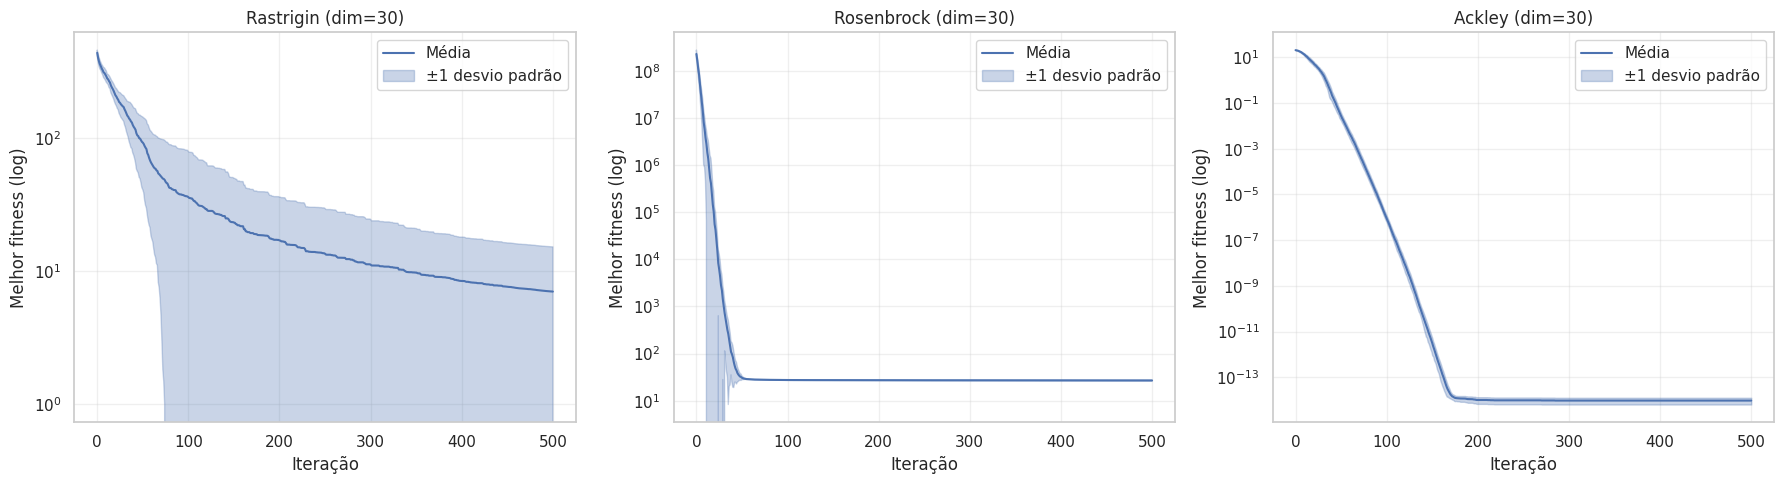

In [ ]:
N_RUNS = 30
N_WOLVES_BASE = 30
MAX_ITER_BASE = 500

resultados_bench = {}

for nome, cfg in BENCHMARKS.items():
    print(f"\n>>> Benchmark: {nome}")
    historicos = []
    finais = []

    for run in tqdm(range(N_RUNS), desc=nome):
        gwo = GWO(
            obj_func=cfg["func"],
            dim=cfg["dim"],
            lb=cfg["lb"],
            ub=cfg["ub"],
            n_wolves=N_WOLVES_BASE,
            max_iter=MAX_ITER_BASE,
            seed=run,
        )
        _, best, hist = gwo.optimize()
        historicos.append(hist)
        finais.append(best)

    historicos = np.array(historicos)   # (N_RUNS, MAX_ITER+1)
    resultados_bench[nome] = {
        "media_hist": historicos.mean(axis=0),
        "std_hist":   historicos.std(axis=0),
        "melhor":     float(np.min(finais)),
        "media":      float(np.mean(finais)),
        "std":        float(np.std(finais)),
    }
    print(f"    melhor={resultados_bench[nome]['melhor']:.4e} | "
          f"média={resultados_bench[nome]['media']:.4e} | "
          f"std={resultados_bench[nome]['std']:.4e}")

# ---- Gráfico ----
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (nome, res) in zip(axes, resultados_bench.items()):
    x = np.arange(len(res["media_hist"]))
    ax.plot(x, res["media_hist"], color="C0", label="Média")
    ax.fill_between(x,
                    res["media_hist"] - res["std_hist"],
                    res["media_hist"] + res["std_hist"],
                    alpha=0.3, color="C0", label="±1 desvio padrão")
    ax.set_yscale("log")
    ax.set_title(f"{nome} (dim=30)")
    ax.set_xlabel("Iteração")
    ax.set_ylabel("Melhor fitness (log)")
    ax.legend()
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("convergencia_benchmarks.png", dpi=150)
plt.show()

## 5. FlowShopEngine

Mantido **sem alterações** conforme instrução. Responsável por:
- Ler instâncias `.txt`
- Decodificar chaves contínuas em permutações (`bucket_sort_decode`)
- Calcular makespan e tardiness

In [ ]:
from pathlib import Pathimport sysrepo_root = Path.cwd()if not (repo_root / "scripts" / "legacy_pfs.py").is_file():    raise FileNotFoundError(        "Strict PFS engine not found. Run this notebook from the repository root "        "or clone rochelAsc/GWO-environment first."    )if str(repo_root) not in sys.path:    sys.path.insert(0, str(repo_root))from scripts.legacy_pfs import FlowShopEngine

## 6. Adaptação do GWO ao FlowShop

O `FlowShopEngine` expõe `bucket_sort_decode(keys)`, que transforma um
vetor contínuo `keys ∈ [0,1]^n` em uma permutação de jobs. Assim,
mantemos o **GWO canônico** (contínuo) e apenas trocamos a função de fitness.

- **Dimensão:** `D = n_jobs`
- **Limites:** `[0, 1]^D`
- **Fitness:** `engine.evaluate(keys, objective="Tardiness")`

In [ ]:
# ============================================================
# SEÇÃO 6: Wrapper GWO ↔ FlowShop
# ============================================================
def fitness_flowshop(engine, keys, objective="Tardiness"):
    """Fitness para o GWO: usa o engine para avaliar a permutação decodificada."""
    return engine.evaluate(keys, objective=objective)


def rodar_gwo_flowshop(caminho_instancia, n_wolves=30, max_iter=200,
                       objective="Tardiness", seed=0, a_decay="linear",
                       verbose=False):
    """
    Executa o GWO em uma instância de FlowShop e retorna métricas.

    Parâmetros
    ----------
    caminho_instancia : str
        Caminho para o arquivo .txt da instância.
    n_wolves : int
        Tamanho da população do GWO.
    max_iter : int
        Número máximo de iterações.
    objective : {"Tardiness", "Makespan"}
        Objetivo a minimizar.
    seed : int or None
        Semente para reprodutibilidade.
    a_decay : {"linear", "exponential", "sqrt"}
        Estratégia de decaimento do coeficiente `a` (2 → 0).
    verbose : bool
        Se True, imprime um resumo da execução.
    """
    # 1) Carrega a instância e cria o engine
    n, m, p, d = FlowShopEngine.carregar_instancia_txt(caminho_instancia)
    engine = FlowShopEngine(n, m, p, d)

    # 2) Define a função objetivo a partir do engine
    obj = lambda keys: fitness_flowshop(engine, keys, objective=objective)

    # 3) Instancia o GWO em espaço contínuo [0,1]^n
    gwo = GWO(
        obj_func=obj,
        dim=n,
        lb=0.0, ub=1.0,
        n_wolves=n_wolves,
        max_iter=max_iter,
        seed=seed,
        a_decay=a_decay,
    )

    # 4) Otimiza
    best_x, best_f, hist = gwo.optimize()

    if verbose:
        print(f"[GWO] {os.path.basename(caminho_instancia):20s} | "
              f"{objective}={best_f:.2f} | evals={gwo.n_evals} | "
              f"n={n}, m={m}, a_decay={a_decay}")

    return {
        "best_fitness": float(best_f),
        "history": hist,
        "n_evals": gwo.n_evals,
        "perm": engine.bucket_sort_decode(best_x),
        "n_jobs": n,
        "n_maquinas": m,
    }


# --- Teste rápido com a instância de exemplo ---
resultado = rodar_gwo_flowshop(
    "instancias/DPFSP_DD/Small/I_4_8_4_3.txt",  # ajuste o caminho se necessário
    n_wolves=30, max_iter=200,
    objective="Tardiness", seed=0, a_decay="linear",
    verbose=True,
)

[GWO] I_4_8_4_3.txt        | Tardiness=1031.00 | evals=6030 | n=8, m=4, a_decay=linear


In [ ]:
# ============================================================
# SEÇÃO 6.5: Seleção estratificada AMPLIADA
# ============================================================
import os, re
import numpy as np
from collections import Counter

def tamanho_instancia(caminho):
    with open(caminho) as f:
        primeira = next(l for l in f if l.strip())
        return tuple(map(int, primeira.split()[:2]))

def listar(pasta):
    return sorted([
        os.path.join(r, f)
        for r, _, fs in os.walk(pasta)
        for f in fs if f.endswith('.txt')
    ])

small_all = listar("instancias/DPFSP_DD/Small")
large_all = listar("instancias/DPFSP_DD/Large")

# Agrupa por tamanho (N, M)
sizes_small = {p: tamanho_instancia(p) for p in small_all}
por_tamanho = {}
for p, sz in sizes_small.items():
    por_tamanho.setdefault(sz, []).append(p)

rng = np.random.default_rng(42)
TREINO, TESTE = [], []

# Seleciona até 2 instâncias por tamanho para teste (totalizando ~20)
for sz, lista in sorted(por_tamanho.items()):
    lista_perm = [lista[i] for i in rng.permutation(len(lista))]
    if len(lista_perm) >= 3:
        TREINO.append(lista_perm[0])
        TESTE.extend(lista_perm[1:3]) # Pega 2 para teste
    elif len(lista_perm) == 2:
        TREINO.append(lista_perm[0])
        TESTE.append(lista_perm[1])

# Limita para não estourar o tempo (20 no máximo)
TESTE = TESTE[:20]

# Generalização: 3 Large de tamanhos variados
sizes_large = {p: tamanho_instancia(p) for p in large_all}
por_tamanho_large = {}
for p, sz in sizes_large.items():
    por_tamanho_large.setdefault(sz, []).append(p)

chaves_ord = sorted(por_tamanho_large.keys())
GERAL = []
# Pega uma de tamanho médio, uma grande e uma muito grande (se existirem)
indices_alvo = [len(chaves_ord)//4, len(chaves_ord)//2, -1]
for idx in indices_alvo:
    if abs(idx) < len(chaves_ord):
        GERAL.append(por_tamanho_large[chaves_ord[idx]][0])

print(f"TREINO: {len(TREINO)} instâncias")
print(f"TESTE:  {len(TESTE)} instâncias (tamanhos variados)")
print(f"GERAL:  {len(GERAL)} instâncias Large")
for p in GERAL: print(f"  {os.path.basename(p)} {tamanho_instancia(p)}")

TREINO: 28 instâncias
TESTE:  20 instâncias (tamanhos variados)
GERAL:  3 instâncias Large
  Ta031_2.txt (50, 5)
  Ta061_2.txt (100, 5)
  Ta111_2.txt (500, 20)


## 7. Sintonia de hiperparâmetros com Optuna

**Objetivo:** encontrar a **melhor combinação fixa** de hiperparâmetros do GWO
que minimize a fitness final média em um conjunto de instâncias de treino.

Hiperparâmetros sintonizados:
- `n_wolves` ∈ [10, 60]
- `max_iter` fixo = 200 (para limitar custo)
- *Opcional:* `a_max` (inicial de `a`), `a_min` (final de `a`) — variantes comuns

**Amostrador:** TPE (`TPESampler`), com seed fixa para reprodutibilidade.

[I 2026-10-26 18:45:57,285] A new study created in memory with name: gwo_flowshop_v2


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-10-26 18:46:48,020] Trial 0 finished with value: 2259.0 and parameters: {'n_wolves': 30, 'a_decay': 'linear'}. Best is trial 0 with value: 2259.0.
[Trial 00] state=COMPLETE | value=2259.00 | best=2259.00 | params={'n_wolves': 30, 'a_decay': 'linear'}
[I 2026-10-26 18:47:14,868] Trial 1 finished with value: 2263.095238095238 and parameters: {'n_wolves': 15, 'a_decay': 'sqrt'}. Best is trial 0 with value: 2259.0.
[Trial 01] state=COMPLETE | value=2263.10 | best=2259.00 | params={'n_wolves': 15, 'a_decay': 'sqrt'}
[I 2026-10-26 18:48:26,804] Trial 2 finished with value: 2247.4523809523807 and parameters: {'n_wolves': 40, 'a_decay': 'sqrt'}. Best is trial 2 with value: 2247.4523809523807.
[Trial 02] state=COMPLETE | value=2247.45 | best=2247.45 | params={'n_wolves': 40, 'a_decay': 'sqrt'}
[I 2026-10-26 18:49:59,654] Trial 3 finished with value: 2246.059523809524 and parameters: {'n_wolves': 55, 'a_decay': 'linear'}. Best is trial 3 with value: 2246.059523809524.
[Trial 03] state=CO

/tmp/ipykernel_1840/2893938692.py:57: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  fig1 = optuna.visualization.matplotlib.plot_optimization_history(study)


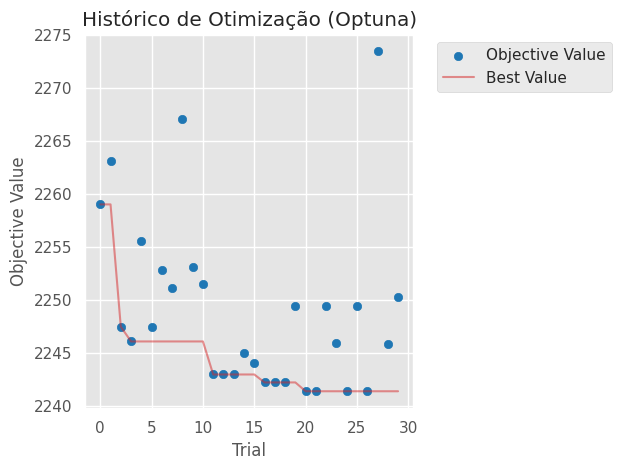

/tmp/ipykernel_1840/2893938692.py:64: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  fig2 = optuna.visualization.matplotlib.plot_param_importances(study)


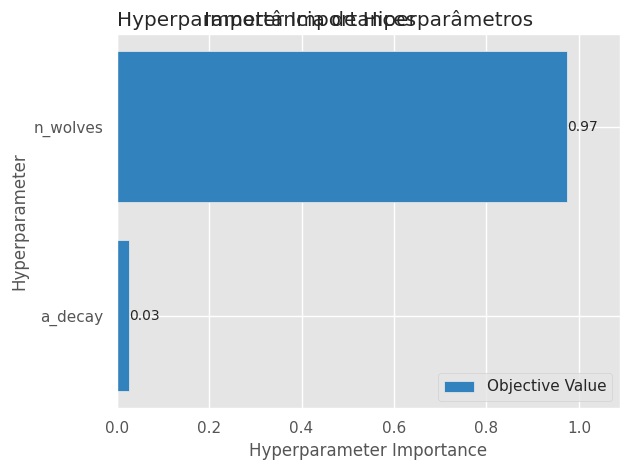

/tmp/ipykernel_1840/2893938692.py:71: ExperimentalWarning: optuna.visualization.matplotlib._slice.plot_slice is experimental (supported from v2.2.0). The interface can change in the future.
  fig3 = optuna.visualization.matplotlib.plot_slice(study)
/tmp/ipykernel_1840/2893938692.py:72: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


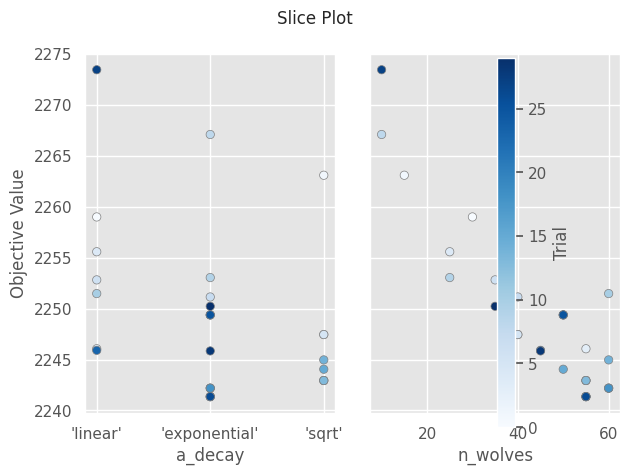


[OK] study salvo em optuna_study.pkl


In [ ]:
# ============================================================
# SEÇÃO 7: Sintonia com Optuna (2 hiperparâmetros: n_wolves + a_decay)
# ============================================================
# INSTANCIAS_TREINO vem da Célula 6.5 (seleção estratificada)
INSTANCIAS_TREINO = TREINO
MAX_ITER_TUNING   = 200
N_TRIALS          = 30
SEEDS_TUNING      = [0, 1, 2]   # média sobre 3 seeds para robustez

def objective_optuna(trial):
    n_wolves = trial.suggest_int("n_wolves", 10, 60, step=5)
    a_decay  = trial.suggest_categorical("a_decay", ["linear", "exponential", "sqrt"])

    fits = []
    for inst in INSTANCIAS_TREINO:
        for s in SEEDS_TUNING:
            r = rodar_gwo_flowshop(
                inst,
                n_wolves=n_wolves,
                max_iter=MAX_ITER_TUNING,
                objective="Tardiness",
                seed=s,
                a_decay=a_decay,
                verbose=False,
            )
            fits.append(r["best_fitness"])
    return float(np.mean(fits))

# Callback para logar o progresso
def _log_trial(study, trial):
    print(f"[Trial {trial.number:02d}] "
          f"state={trial.state.name} | "
          f"value={trial.value if trial.value is not None else float('nan'):.2f} | "
          f"best={study.best_value:.2f} | params={trial.params}")

study = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=42),
    study_name="gwo_flowshop_v2",
)
study.optimize(
    objective_optuna,
    n_trials=N_TRIALS,
    show_progress_bar=True,
    callbacks=[_log_trial],
)

print("\n=== Melhor trial ===")
print(f"  n_wolves = {study.best_params['n_wolves']}")
print(f"  a_decay  = {study.best_params['a_decay']}")
print(f"  fitness  = {study.best_value:.4f}")

# ---- Artefatos exigidos pelo professor ----
import matplotlib.pyplot as plt

# 1) Histórico de otimização
fig1 = optuna.visualization.matplotlib.plot_optimization_history(study)
plt.title("Histórico de Otimização (Optuna)")
plt.tight_layout()
plt.savefig("optuna_history.png", dpi=150)
plt.show()

# 2) Importância de hiperparâmetros
fig2 = optuna.visualization.matplotlib.plot_param_importances(study)
plt.title("Importância de Hiperparâmetros")
plt.tight_layout()
plt.savefig("optuna_importance.png", dpi=150)
plt.show()

# 3) Bônus: slice plot (útil no relatório)
fig3 = optuna.visualization.matplotlib.plot_slice(study)
plt.tight_layout()
plt.savefig("optuna_slice.png", dpi=150)
plt.show()

# Salva o study para retomar se o Colab cair
import pickle
with open("optuna_study.pkl", "wb") as f:
    pickle.dump(study, f)
print("\n[OK] study salvo em optuna_study.pkl")


## 8. Comparação Baseline × Sintetizado

**Baseline** (literatura): `n_wolves=30`, `max_iter=200`
**Sintetizado** (Optuna): melhor `n_wolves` encontrado

Avaliação em 30 execuções independentes na mesma instância de teste.

>>> Iniciando testes em Instâncias SMALL (30 seeds, 4 configs)...


Progresso Small:   0%|          | 0/20 [00:00<?, ?instância/s]

  ↳ Rodando Baseline (n=30, linear) em I_3_4_2_3.txt...
  ↳ Rodando Tunado (n=55, exp) em I_3_4_2_3.txt...
  ↳ Rodando Ablação (n=30, exp) em I_3_4_2_3.txt...
  ↳ Rodando Ablação (n=55, linear) em I_3_4_2_3.txt...
  ↳ Rodando Baseline (n=30, linear) em I_3_4_2_5.txt...
  ↳ Rodando Tunado (n=55, exp) em I_3_4_2_5.txt...
  ↳ Rodando Ablação (n=30, exp) em I_3_4_2_5.txt...
  ↳ Rodando Ablação (n=55, linear) em I_3_4_2_5.txt...
  ↳ Rodando Baseline (n=30, linear) em I_4_4_3_4.txt...
  ↳ Rodando Tunado (n=55, exp) em I_4_4_3_4.txt...
  ↳ Rodando Ablação (n=30, exp) em I_4_4_3_4.txt...
  ↳ Rodando Ablação (n=55, linear) em I_4_4_3_4.txt...
  ↳ Rodando Baseline (n=30, linear) em I_3_4_3_4.txt...
  ↳ Rodando Tunado (n=55, exp) em I_3_4_3_4.txt...
  ↳ Rodando Ablação (n=30, exp) em I_3_4_3_4.txt...
  ↳ Rodando Ablação (n=55, linear) em I_3_4_3_4.txt...
  ↳ Rodando Baseline (n=30, linear) em I_2_4_4_3.txt...
  ↳ Rodando Tunado (n=55, exp) em I_2_4_4_3.txt...
  ↳ Rodando Ablação (n=30, exp) em I_

Progresso Large:   0%|          | 0/3 [00:00<?, ?instância/s]

  ↳ Rodando Baseline (n=30, linear) em Ta031_2.txt...
  ↳ Rodando Tunado (n=55, exp) em Ta031_2.txt...
  ↳ Rodando Baseline (n=30, linear) em Ta061_2.txt...
  ↳ Rodando Tunado (n=55, exp) em Ta061_2.txt...
  ↳ Rodando Baseline (n=30, linear) em Ta111_2.txt...
  ↳ Rodando Tunado (n=55, exp) em Ta111_2.txt...

Gerando planilhas e processando dados...
[OK] Planilha 'resultados_completos_gwo.xlsx' salva.

--- RESUMO (Instâncias Small) ---
                          Media  Mediana  Desvio  Melhor  Tempo_Medio_s
Configuracao                                                           
Ablação (n=30, exp)      569.95    560.0  308.50   173.0           0.38
Ablação (n=55, linear)   569.57    560.0  308.08   173.0           0.71
Baseline (n=30, linear)  570.24    560.0  308.69   173.0           0.39
Tunado (n=55, exp)       569.29    560.0  307.74   173.0           0.71

Gerando gráficos...


/tmp/ipykernel_1840/1736470260.py:116: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_small, x="Configuracao", y="Fitness_Final", palette="Set2")


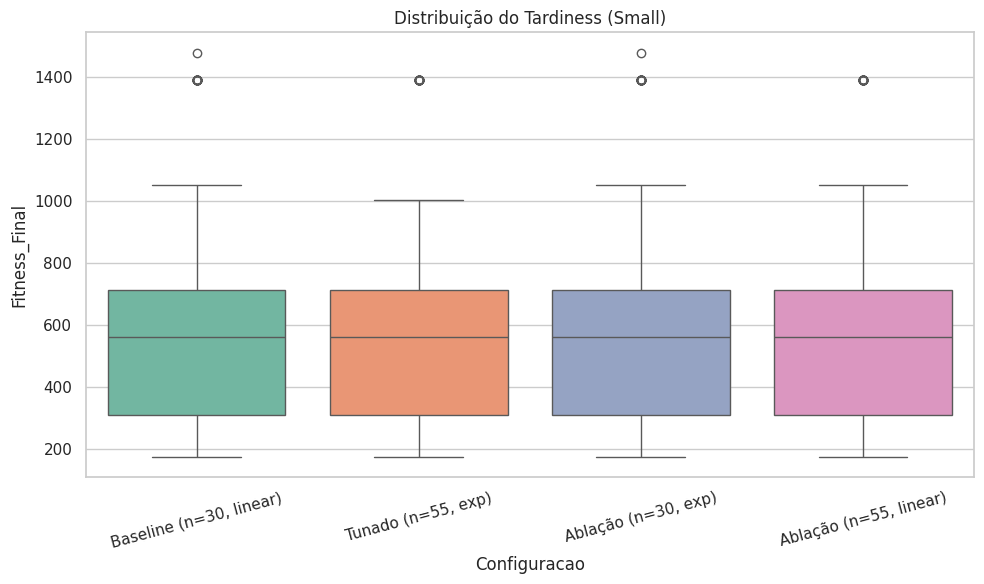

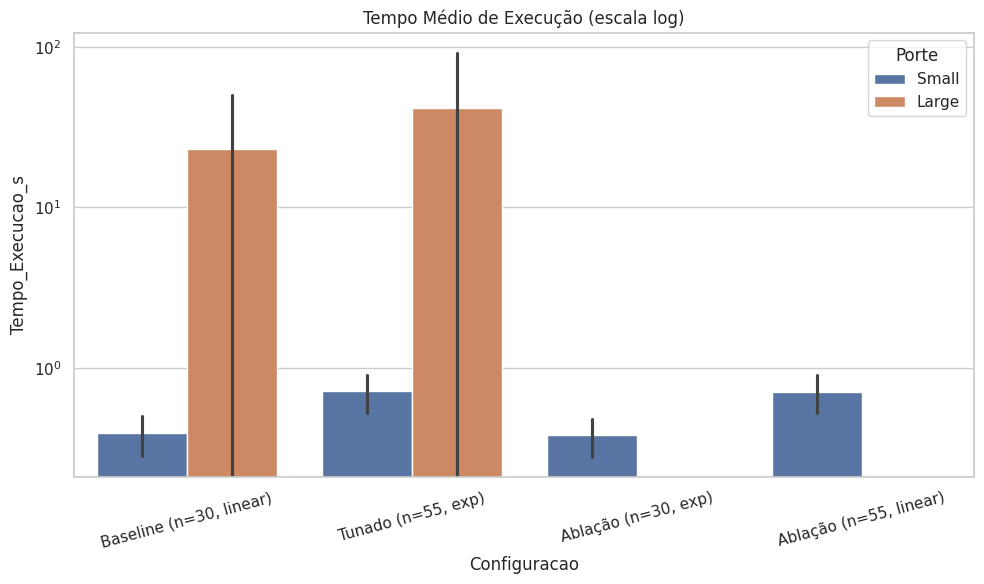

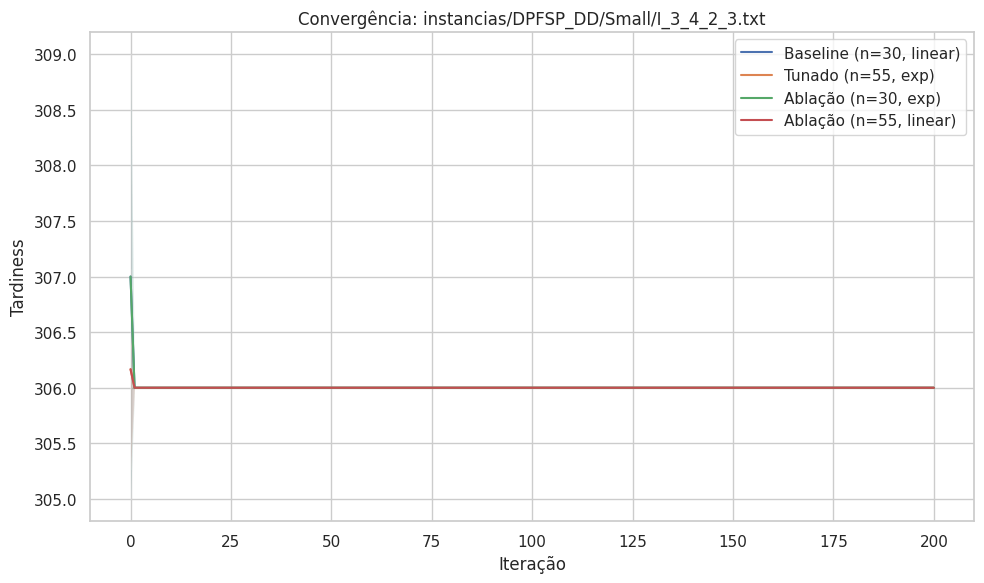


✅ Processo finalizado com sucesso!


In [ ]:
# ============================================================
# SEÇÃO 8: Avaliação Otimizada com Progresso Visível
# ============================================================
import pandas as pd
import time
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm  # Garante que a barra de progresso esteja disponível

# 1. Definição de Configurações
configs_small = [
    {"nome": "Baseline (n=30, linear)", "n": 30, "decay": "linear"},
    {"nome": "Tunado (n=55, exp)", "n": 55, "decay": "exponential"},
    {"nome": "Ablação (n=30, exp)", "n": 30, "decay": "exponential"},
    {"nome": "Ablação (n=55, linear)", "n": 55, "decay": "linear"}
]

configs_large = [
    {"nome": "Baseline (n=30, linear)", "n": 30, "decay": "linear"},
    {"nome": "Tunado (n=55, exp)", "n": 55, "decay": "exponential"}
]

dados_completos = []
historicos_para_grafico = {}

print(">>> Iniciando testes em Instâncias SMALL (30 seeds, 4 configs)...")
# tqdm envolve a lista TESTE para mostrar o progresso (ex: 1/20, 2/20...)
for inst in tqdm(TESTE, desc="Progresso Small", unit="instância"):
    n, m = tamanho_instancia(inst)
    inst_nome = os.path.basename(inst)
    guardar_hist = (inst == TESTE[0])

    for cfg in configs_small:
        # Log para indicar qual config está rodando na instância atual
        tqdm.write(f"  ↳ Rodando {cfg['nome']} em {inst_nome}...")

        for seed in range(30):
            t0 = time.time()
            res = rodar_gwo_flowshop(inst, n_wolves=cfg["n"], a_decay=cfg["decay"],
                                     max_iter=MAX_ITER_TUNING, seed=seed, verbose=False)
            t_exec = time.time() - t0

            dados_completos.append({
                "Instancia": inst_nome, "Porte": "Small", "N_Jobs": n, "N_Maquinas": m,
                "Configuracao": cfg["nome"], "n_wolves": cfg["n"], "a_decay": cfg["decay"],
                "Seed": seed, "Fitness_Final": res["best_fitness"],
                "Tempo_Execucao_s": t_exec, "Avaliacoes_Funcao": res["n_evals"]
            })
            if guardar_hist:
                historicos_para_grafico.setdefault(cfg["nome"], []).append(res["history"])

print("\n>>> Iniciando testes em Instâncias LARGE (10 seeds, 2 configs)...")
for inst in tqdm(GERAL, desc="Progresso Large", unit="instância"):
    n, m = tamanho_instancia(inst)
    inst_nome = os.path.basename(inst)

    for cfg in configs_large:
        tqdm.write(f"  ↳ Rodando {cfg['nome']} em {inst_nome}...")

        for seed in range(10): # Reduzido para 10 seeds
            t0 = time.time()
            res = rodar_gwo_flowshop(inst, n_wolves=cfg["n"], a_decay=cfg["decay"],
                                     max_iter=MAX_ITER_TUNING, seed=seed, verbose=False)
            t_exec = time.time() - t0

            dados_completos.append({
                "Instancia": inst_nome, "Porte": "Large", "N_Jobs": n, "N_Maquinas": m,
                "Configuracao": cfg["nome"], "n_wolves": cfg["n"], "a_decay": cfg["decay"],
                "Seed": seed, "Fitness_Final": res["best_fitness"],
                "Tempo_Execucao_s": t_exec, "Avaliacoes_Funcao": res["n_evals"]
            })

# 2. Criação da Planilha Legendada
print("\nGerando planilhas e processando dados...")
df_full = pd.DataFrame(dados_completos)

df_legenda = pd.DataFrame({
    "Coluna": ["Instancia", "Porte", "N_Jobs", "N_Maquinas", "Configuracao",
               "n_wolves", "a_decay", "Seed", "Fitness_Final", "Tempo_Execucao_s", "Avaliacoes_Funcao"],
    "Descricao": [
        "Nome do arquivo .txt da instância",
        "Categoria: 'Small' (treino/teste) ou 'Large' (generalização)",
        "Número de jobs (trabalhos)",
        "Número de máquinas",
        "Configuração do GWO (Baseline, Tunado, Ablações)",
        "Tamanho da população (lobos)",
        "Decaimento do coeficiente 'a' (linear ou exponential)",
        "Semente aleatória",
        "Tardiness final (menor é melhor)",
        "Tempo de execução em segundos",
        "Total de chamadas ao FlowShopEngine"
    ]
})

with pd.ExcelWriter("resultados_completos_gwo.xlsx", engine='openpyxl') as writer:
    df_full.to_excel(writer, sheet_name="Dados_Brutos", index=False)
    df_legenda.to_excel(writer, sheet_name="Legenda", index=False)
print("[OK] Planilha 'resultados_completos_gwo.xlsx' salva.")

# 3. Tabela Resumo (Small)
df_small = df_full[df_full["Porte"] == "Small"]
resumo_small = df_small.groupby("Configuracao").agg(
    Media=("Fitness_Final", "mean"), Mediana=("Fitness_Final", "median"),
    Desvio=("Fitness_Final", "std"), Melhor=("Fitness_Final", "min"),
    Tempo_Medio_s=("Tempo_Execucao_s", "mean")
).round(2)
print("\n--- RESUMO (Instâncias Small) ---")
print(resumo_small)
resumo_small.to_csv("resumo_small.csv")

# 4. Geração de Gráficos
print("\nGerando gráficos...")
sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))
sns.boxplot(data=df_small, x="Configuracao", y="Fitness_Final", palette="Set2")
plt.title("Distribuição do Tardiness (Small)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("boxplot_fitness_small.png", dpi=150)
plt.show()

plt.figure(figsize=(10, 6))
sns.barplot(data=df_full, x="Configuracao", y="Tempo_Execucao_s", hue="Porte", errorbar="sd")
plt.yscale("log")
plt.title("Tempo Médio de Execução (escala log)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("barplot_tempo.png", dpi=150)
plt.show()

plt.figure(figsize=(10, 6))
for cfg_nome, hists in historicos_para_grafico.items():
    hists = np.array(hists)
    media, std = hists.mean(axis=0), hists.std(axis=0)
    plt.plot(np.arange(len(media)), media, label=cfg_nome)
    plt.fill_between(np.arange(len(media)), media - std, media + std, alpha=0.1)
plt.title(f"Convergência: {TESTE[0]}")
plt.xlabel("Iteração"); plt.ylabel("Tardiness")
plt.legend(); plt.tight_layout()
plt.savefig("convergencia_flowshop.png", dpi=150)
plt.show()

print("\n✅ Processo finalizado com sucesso!")

>>> Calculando GAP (Lower Bound) e Testes Estatísticos...

--- Teste Estatístico (Wilcoxon) ---
Wilcoxon (Mediana por instância): p-value = 1.0881e-01
⚠️ Diferença NÃO significativa (p >= 0.05)

>>> Gerando gráfico de barras por instância...


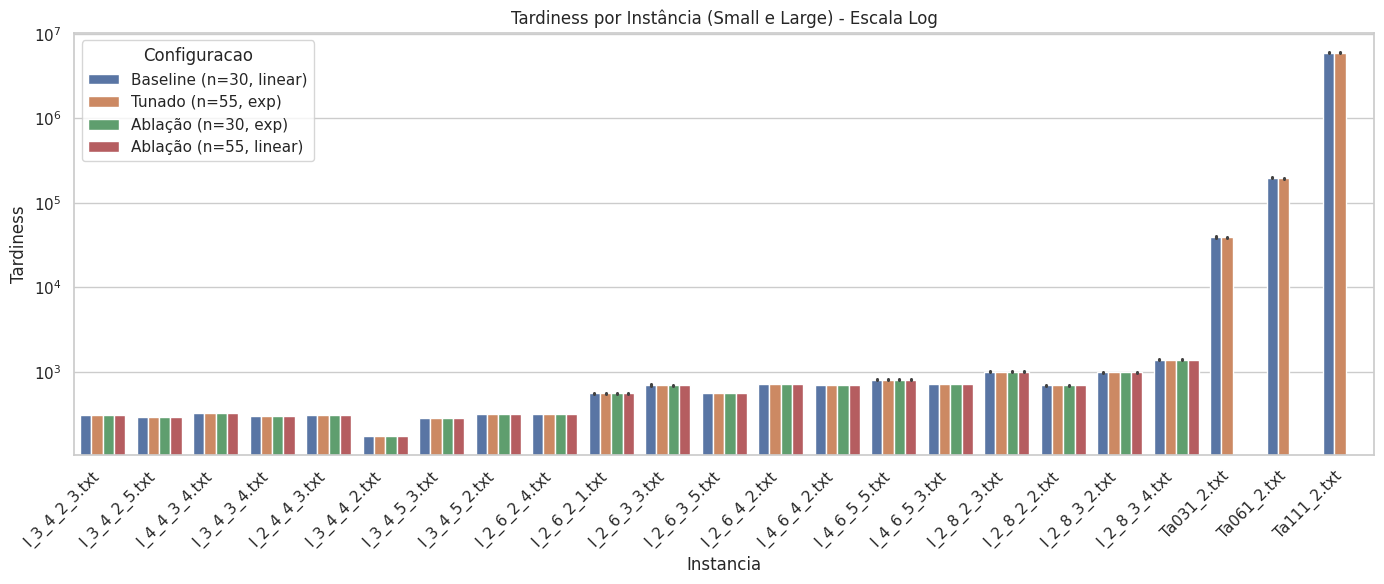

✅ Extras gerados com sucesso!


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import wilcoxon, friedmanchisquare
import os

print(">>> Calculando GAP (Lower Bound) e Testes Estatísticos...")

# 1. Calcular o Lower Bound (Potts) para as instâncias de teste
# O FlowShopEngine do professor tem esse método estático
gaps = []
for inst in TESTE:
    n, m, p, d = FlowShopEngine.carregar_instancia_txt(inst)
    lb = FlowShopEngine.calcular_lower_bound_potts(n, m, p, d)

    # Pegar os resultados do df_full para essa instância
    df_inst = df_full[df_full["Instancia"] == os.path.basename(inst)]
    for _, row in df_inst.iterrows():
        gap = ((row["Fitness_Final"] - lb) / lb) * 100 if lb > 0 else 0
        gaps.append({
            "Instancia": row["Instancia"], "Configuracao": row["Configuracao"],
            "Seed": row["Seed"], "Fitness": row["Fitness_Final"],
            "LowerBound": lb, "GAP_%": gap
        })

df_gap = pd.DataFrame(gaps)
df_gap.to_csv("gaps_lower_bound.csv", index=False)

# 2. Teste de Wilcoxon (Baseline vs Tunado)
print("\n--- Teste Estatístico (Wilcoxon) ---")
df_base = df_full[df_full["Configuracao"] == "Baseline (n=30, linear)"].groupby("Instancia")["Fitness_Final"].median()
df_tun  = df_full[df_full["Configuracao"] == "Tunado (n=55, exp)"].groupby("Instancia")["Fitness_Final"].median()

stat, p_value = wilcoxon(df_base, df_tun)
print(f"Wilcoxon (Mediana por instância): p-value = {p_value:.4e}")
if p_value < 0.05:
    print("✅ Diferença ESTATISTICAMENTE SIGNIFICATIVA (p < 0.05)")
else:
    print("⚠️ Diferença NÃO significativa (p >= 0.05)")

with open("teste_estatistico.txt", "w") as f:
    f.write(f"Teste de Wilcoxon (Baseline vs Tunado)\nEstatística: {stat}\np-value: {p_value}\n")
    f.write("Conclusão: " + ("Significativo" if p_value < 0.05 else "Não significativo") + "\n")

# 3. Gerar o Gráfico Faltante (Barras por Instância)
print("\n>>> Gerando gráfico de barras por instância...")
plt.figure(figsize=(14, 6))
sns.barplot(data=df_full, x="Instancia", y="Fitness_Final", hue="Configuracao", errorbar="sd")
plt.yscale("log")
plt.title("Tardiness por Instância (Small e Large) - Escala Log")
plt.ylabel("Tardiness")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("barras_por_instancia.png", dpi=150)
plt.show()

print("✅ Extras gerados com sucesso!")

In [ ]:
from google.colab import files
import os

# Lista com TUDO o que pode ter sido gerado no projeto
todos_artefatos = [
    # Semana 2
    "convergencia_benchmarks.png",
    # Optuna
    "optuna_history.png", "optuna_importance.png", "optuna_slice.png", "optuna_study.pkl",
    # Dados Brutos e Resumos (Célula 8 v3.1)
    "resultados_completos_gwo.xlsx", "resumo_small.csv",
    # Gráficos Principais
    "boxplot_fitness_small.png", "barplot_tempo.png", "convergencia_flowshop.png",
    # Dados Extras (Célula 8.5)
    "gaps_lower_bound.csv", "teste_estatistico.txt", "barras_por_instancia.png"
]

print("📦 Iniciando download de todos os artefatos disponíveis...\n")
baixados = 0

for f in todos_artefatos:
    if os.path.exists(f):
        try:
            files.download(f)
            print(f"✅ [OK] Baixado: {f}")
            baixados += 1
        except Exception as e:
            print(f"❌ [ERRO] Não foi possível baixar {f}: {e}")
    else:
        print(f"⚠️ [FALTA] {f} (Não foi gerado nesta sessão)")

print(f"\n🎉 Concluído! {baixados} arquivos baixados.")

📦 Iniciando download de todos os artefatos disponíveis...



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ [OK] Baixado: convergencia_benchmarks.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (30 outputs left out)

✅ [OK] Baixado: teste_estatistico.txt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ [OK] Baixado: barras_por_instancia.png

🎉 Concluído! 13 arquivos baixados.


In [ ]:
import pandas as pd
import os
from google.colab import files

print(">>> Unificando todos os dados em um único arquivo Excel...")

arquivo_mestre = "relatorio_final_gwo.xlsx"

# 1. Carrega os dados
df_brutos = pd.read_excel("resultados_completos_gwo.xlsx", sheet_name="Dados_Brutos")
df_resumo = pd.read_csv("resumo_small.csv")
df_gaps   = pd.read_csv("gaps_lower_bound.csv")

# 2. Prepara a aba de Testes Estatísticos
with open("teste_estatistico.txt", "r") as f:
    linhas_teste = f.readlines()

df_testes = pd.DataFrame({
    "Teste": ["Wilcoxon (Baseline vs Tunado)"],
    "Estatística": [linhas_teste[1].split(":")[1].strip()],
    "p-value": [linhas_teste[2].split(":")[1].strip()],
    "Conclusão": [linhas_teste[3].split(":")[1].strip()]
})

# 3. Legenda Expandida (estrutura de tuplas: Aba, Coluna, Descrição)
legenda_tuplas = [
    # Dados Brutos
    ("1_Dados_Brutos", "Instancia", "Nome do arquivo da instância"),
    ("1_Dados_Brutos", "Porte", "Categoria: Small ou Large"),
    ("1_Dados_Brutos", "N_Jobs", "Número de Jobs (trabalhos)"),
    ("1_Dados_Brutos", "N_Maquinas", "Número de Máquinas"),
    ("1_Dados_Brutos", "Configuracao", "Nome da configuração do GWO avaliada"),
    ("1_Dados_Brutos", "n_wolves", "Tamanho da população (número de lobos)"),
    ("1_Dados_Brutos", "a_decay", "Estratégia de decaimento do coeficiente 'a'"),
    ("1_Dados_Brutos", "Seed", "Semente aleatória da execução"),
    ("1_Dados_Brutos", "Fitness_Final", "Tardiness final obtido (menor é melhor)"),
    ("1_Dados_Brutos", "Tempo_Execucao_s", "Tempo de execução em segundos"),
    ("1_Dados_Brutos", "Avaliacoes_Funcao", "Qtd de chamadas ao FlowShopEngine"),
    # Resumo Small
    ("2_Resumo_Small", "Configuracao", "Configuração do GWO"),
    ("2_Resumo_Small", "Media", "Média do Tardiness nas 30 sementes"),
    ("2_Resumo_Small", "Mediana", "Mediana do Tardiness"),
    ("2_Resumo_Small", "Desvio", "Desvio padrão das execuções"),
    ("2_Resumo_Small", "Melhor", "Melhor resultado obtido"),
    ("2_Resumo_Small", "Tempo_Medio_s", "Tempo médio de execução (s)"),
    # GAP
    ("3_GAP_LowerBound", "Instancia", "Nome da instância"),
    ("3_GAP_LowerBound", "Configuracao", "Configuração do GWO"),
    ("3_GAP_LowerBound", "Seed", "Semente da execução"),
    ("3_GAP_LowerBound", "Fitness", "Tardiness obtido"),
    ("3_GAP_LowerBound", "LowerBound", "Limite inferior teórico (McMahon-Florian-Potts)"),
    ("3_GAP_LowerBound", "GAP_%", "Distância percentual do ótimo teórico (%)"),
    # Testes Estatísticos
    ("4_Testes_Estatisticos", "Teste", "Nome do teste aplicado"),
    ("4_Testes_Estatisticos", "Estatística", "Valor da estatística do teste"),
    ("4_Testes_Estatisticos", "p-value", "Nível descritivo (significância)"),
    ("4_Testes_Estatisticos", "Conclusão", "Resultado da hipótese (p < 0.05)"),
]

df_legenda_completa = pd.DataFrame(legenda_tuplas, columns=["Aba", "Coluna", "Descricao"])

# 4. Salva tudo no arquivo mestre
with pd.ExcelWriter(arquivo_mestre, engine='openpyxl') as writer:
    df_legenda_completa.to_excel(writer, sheet_name="0_Legenda", index=False)
    df_brutos.to_excel(writer, sheet_name="1_Dados_Brutos", index=False)
    df_resumo.to_excel(writer, sheet_name="2_Resumo_Small", index=False)
    df_gaps.to_excel(writer, sheet_name="3_GAP_LowerBound", index=False)
    df_testes.to_excel(writer, sheet_name="4_Testes_Estatisticos", index=False)

print(f"✅ Arquivo mestre gerado: {arquivo_mestre}")
print(f"   Total de entradas na legenda: {len(df_legenda_completa)}")

files.download(arquivo_mestre)

>>> Unificando todos os dados em um único arquivo Excel...
✅ Arquivo mestre gerado: relatorio_final_gwo.xlsx
   Total de entradas na legenda: 27


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


## 9. Surrogate Model - Rede Neural


Gerando 500 amostras LHS para a instância I_3_4_2_3.txt...


Avaliando amostras:   0%|          | 0/500 [00:00<?, ?it/s]


Treinando a Rede Neural (MLP)...

--- Métricas de Regressão do Surrogate ---
MSE:  605.1437
RMSE: 24.5997
R²:   0.8791


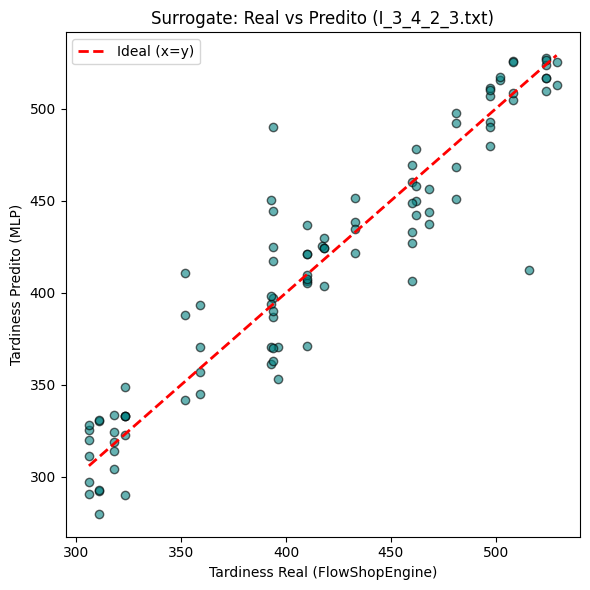


--- Comparando Tempo de Execução (GWO) ---
Tempo com Avaliação Real:      0.22 s
Tempo com Avaliação Surrogate: 1.32 s

Ganho de Velocidade: 0.2x mais rápido
Fitness Real (alcançado pelo GWO real):      306.00
Fitness Surrogate (predito pela MLP):         265.96

✅ Métricas do Surrogate salvas em 'resultados_surrogate.csv'


In [ ]:
# ============================================================
# SEÇÃO 9: Surrogate Model (LHS + Rede Neural MLP)
# ============================================================
!pip install scikit-optimize scikit-learn -q

import numpy as np
import pandas as pd
import time
import matplotlib.pyplot as plt
from scipy.stats import qmc
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tqdm.auto import tqdm

# 1. Configuração da Instância e Coleta de Dados (LHS)
inst_s = TESTE[0]
inst_nome = os.path.basename(inst_s)
n_s, m_s, p_s, d_s = FlowShopEngine.carregar_instancia_txt(inst_s)
engine_s = FlowShopEngine(n_s, m_s, p_s, d_s)

N_SAMPLES = 500
print(f"Gerando {N_SAMPLES} amostras LHS para a instância {inst_nome}...")

# Latin Hypercube Sampling no espaço contínuo [0, 1]^D
sampler = qmc.LatinHypercube(d=n_s, seed=42)
sample = sampler.random(n=N_SAMPLES)

X_data, y_data = [], []
for i in tqdm(range(N_SAMPLES), desc="Avaliando amostras"):
    keys = sample[i]
    # Avalia no FlowShopEngine real
    tardiness = engine_s.evaluate(keys, objective="Tardiness")
    X_data.append(keys)
    y_data.append(tardiness)

X_data = np.array(X_data)
y_data = np.array(y_data).reshape(-1, 1)

# 2. Divisão Treino/Teste e Normalização
X_train, X_test, y_train, y_test = train_test_split(X_data, y_data, test_size=0.2, random_state=42)

# Normalizar a saída (Tardiness) ajuda o MLP a convergir mais rápido e melhor
scaler_y = StandardScaler()
y_train_scaled = scaler_y.fit_transform(y_train)
y_test_scaled = scaler_y.transform(y_test)

# 3. Treinamento da Rede Neural (MLP)
print("\nTreinando a Rede Neural (MLP)...")
mlp = MLPRegressor(
    hidden_layer_sizes=(64, 64), # 2 camadas ocultas com 64 neurônios
    activation='relu',
    solver='adam',
    max_iter=1000,
    random_state=42
)
mlp.fit(X_train, y_train_scaled.ravel())

# 4. Avaliação e Métricas
y_pred_scaled = mlp.predict(X_test)
y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).flatten()
y_test_real = y_test.flatten()

mse = mean_squared_error(y_test_real, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_real, y_pred)

print("\n--- Métricas de Regressão do Surrogate ---")
print(f"MSE:  {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")

# Gráfico de Paridade (Real vs Predito)
plt.figure(figsize=(6, 6))
plt.scatter(y_test_real, y_pred, alpha=0.6, color='teal', edgecolors='k')
plt.plot([y_test_real.min(), y_test_real.max()], [y_test_real.min(), y_test_real.max()], 'r--', lw=2, label='Ideal (x=y)')
plt.title(f"Surrogate: Real vs Predito ({inst_nome})")
plt.xlabel("Tardiness Real (FlowShopEngine)")
plt.ylabel("Tardiness Predito (MLP)")
plt.legend()
plt.tight_layout()
plt.savefig("surrogate_paridade.png", dpi=150)
plt.show()

# 5. Integração com o GWO
# Função de fitness que usa a Rede Neural (muito mais rápida)
def fitness_surrogate(keys):
    keys_2d = keys.reshape(1, -1)
    pred_scaled = mlp.predict(keys_2d)
    pred_real = scaler_y.inverse_transform(pred_scaled.reshape(-1, 1))[0][0]
    return pred_real

print("\n--- Comparando Tempo de Execução (GWO) ---")
# Rodando GWO com avaliação REAL
t0 = time.time()
gwo_real = GWO(obj_func=lambda k: engine_s.evaluate(k, objective="Tardiness"),
               dim=n_s, lb=0.0, ub=1.0, n_wolves=30, max_iter=100, seed=0)
best_real = gwo_real.optimize()[1]
t_real = time.time() - t0
print(f"Tempo com Avaliação Real:      {t_real:.2f} s")

# Rodando GWO com avaliação SURROGATE (Rede Neural)
t0 = time.time()
gwo_surr = GWO(obj_func=fitness_surrogate,
               dim=n_s, lb=0.0, ub=1.0, n_wolves=30, max_iter=100, seed=0)
best_surr = gwo_surr.optimize()[1]
t_surr = time.time() - t0
print(f"Tempo com Avaliação Surrogate: {t_surr:.2f} s")

print(f"\nGanho de Velocidade: {t_real / t_surr:.1f}x mais rápido")
print(f"Fitness Real (alcançado pelo GWO real):      {best_real:.2f}")
print(f"Fitness Surrogate (predito pela MLP):         {best_surr:.2f}")

# 6. Salvar Métricas para a Semana 6
df_surrogate = pd.DataFrame([{
    "Instancia": inst_nome,
    "N_Amostras_LHS": N_SAMPLES,
    "MSE": mse,
    "RMSE": rmse,
    "R2": r2,
    "Tempo_Real_s": t_real,
    "Tempo_Surrogate_s": t_surr,
    "Ganho_Tempo_x": t_real / t_surr,
    "Fitness_Real": best_real,
    "Fitness_Surrogate": best_surr
}])
df_surrogate.to_csv("resultados_surrogate.csv", index=False)
print("\n✅ Métricas do Surrogate salvas em 'resultados_surrogate.csv'")

# 10. Controle Fuzzy Adaptativo



Configurando o Sistema Fuzzy...
Rodando GWO com Controle Fuzzy...
Fitness Final (Fuzzy GWO): 306.00


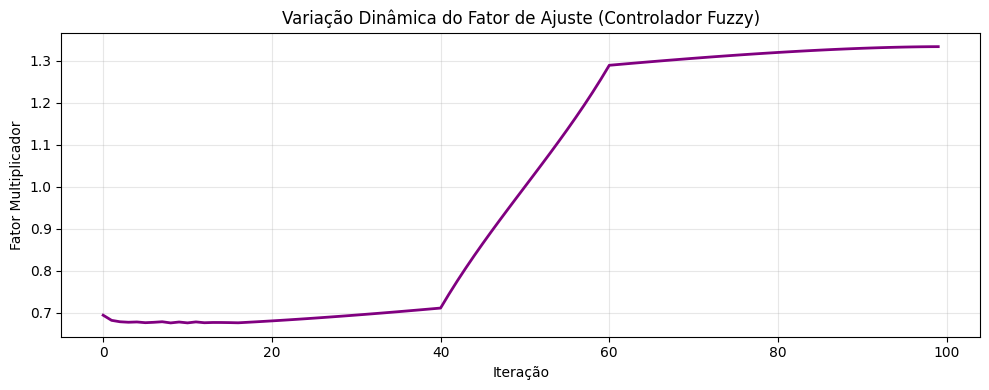

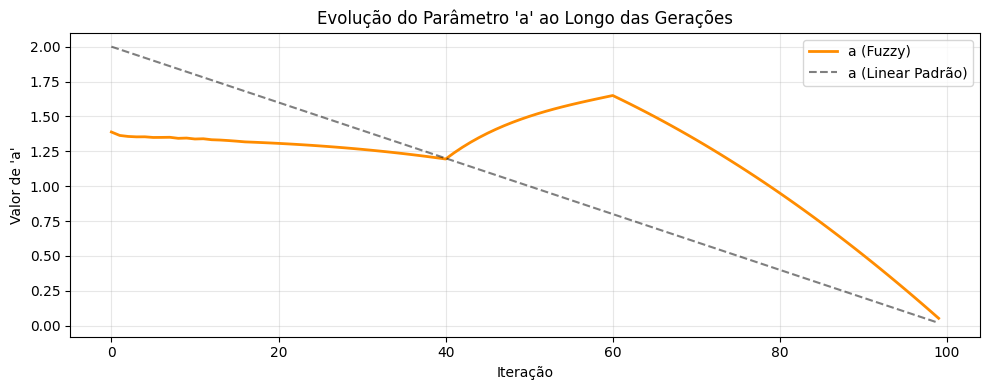

✅ Histórico do Fuzzy salvo em 'historico_fuzzy.csv'


In [ ]:
# ============================================================
# SEÇÃO 10: Controle Fuzzy Adaptativo (Mamdani) - CORRIGIDO
# ============================================================
!pip install scikit-fuzzy -q

import numpy as np
import pandas as pd
import skfuzzy as fuzz
from skfuzzy import control as ctrl
import matplotlib.pyplot as plt

print("Configurando o Sistema Fuzzy...")

# 1. Definição das Variáveis
div = ctrl.Antecedent(np.arange(0, 1.1, 0.1), 'diversidade')
est = ctrl.Antecedent(np.arange(0, 101, 1), 'estagnacao')
ajuste = ctrl.Consequent(np.arange(0.5, 1.6, 0.1), 'ajuste')

# 2. Funções de Pertinência (com SOBREPOSIÇÃO para evitar KeyError)
# A sobreposição garante que sempre haverá pelo menos uma regra ativa
div['baixa'] = fuzz.trimf(div.universe, [0, 0, 0.6])
div['alta']  = fuzz.trimf(div.universe, [0.4, 1, 1])

est['baixa'] = fuzz.trimf(est.universe, [0, 0, 60])
est['alta']  = fuzz.trimf(est.universe, [40, 100, 100])

ajuste['diminuir'] = fuzz.trimf(ajuste.universe, [0.5, 0.5, 1.0])
ajuste['manter']   = fuzz.trimf(ajuste.universe, [0.75, 1.0, 1.25])
ajuste['aumentar'] = fuzz.trimf(ajuste.universe, [1.0, 1.5, 1.5])

# 3. Base de Regras
regra1 = ctrl.Rule(div['baixa'] & est['alta'], ajuste['aumentar'])
regra2 = ctrl.Rule(div['alta'] & est['baixa'], ajuste['diminuir'])
regra3 = ctrl.Rule(div['baixa'] & est['baixa'], ajuste['diminuir'])
regra4 = ctrl.Rule(div['alta'] & est['alta'], ajuste['manter'])

sistema_fuzzy = ctrl.ControlSystem([regra1, regra2, regra3, regra4])
simulador = ctrl.ControlSystemSimulation(sistema_fuzzy)

# 4. Classe GWO com Controle Fuzzy
class GWO_Fuzzy(GWO):
    def optimize(self):
        rng = np.random.default_rng(self.seed)
        positions = rng.uniform(self.lb, self.ub, size=(self.n_wolves, self.dim))
        fitness = np.array([self._eval(p) for p in positions])

        order = np.argsort(fitness)
        alpha_pos, alpha_score = positions[order[0]].copy(), fitness[order[0]]
        beta_pos, beta_score = positions[order[1]].copy(), fitness[order[1]]
        delta_pos, delta_score = positions[order[2]].copy(), fitness[order[2]]

        self.history = [alpha_score]
        self.hist_ajuste = []
        self.hist_a = []

        stagnation_count = 0

        for t in range(self.max_iter):
            # Diversidade normalizada entre 0 e 1
            diversidade = np.mean(np.std(positions, axis=0) / (self.ub - self.lb))
            diversidade = np.clip(diversidade, 0, 1)

            # Inferência Fuzzy com proteção
            simulador.input['diversidade'] = diversidade
            simulador.input['estagnacao'] = min(stagnation_count, 100)

            try:
                simulador.compute()
                fator_ajuste = simulador.output['ajuste']
            except KeyError:
                # Fallback: se nenhuma regra disparar, mantém o 'a' original (fator 1.0)
                fator_ajuste = 1.0

            a_base = self._compute_a(t)
            a = np.clip(a_base * fator_ajuste, 0, 2.0)

            self.hist_ajuste.append(fator_ajuste)
            self.hist_a.append(a)

            melhoria = False
            for i in range(self.n_wolves):
                for d in range(self.dim):
                    r1, r2 = rng.random(), rng.random()
                    A1 = 2 * a * r1 - a
                    C1 = 2 * r2
                    X1 = alpha_pos[d] - A1 * abs(C1 * alpha_pos[d] - positions[i, d])

                    r1, r2 = rng.random(), rng.random()
                    A2 = 2 * a * r1 - a
                    C2 = 2 * r2
                    X2 = beta_pos[d] - A2 * abs(C2 * beta_pos[d] - positions[i, d])

                    r1, r2 = rng.random(), rng.random()
                    A3 = 2 * a * r1 - a
                    C3 = 2 * r2
                    X3 = delta_pos[d] - A3 * abs(C3 * delta_pos[d] - positions[i, d])

                    positions[i, d] = (X1 + X2 + X3) / 3.0

                positions[i] = np.clip(positions[i], self.lb, self.ub)
                fit = self._eval(positions[i])

                if fit < alpha_score:
                    delta_pos, delta_score = beta_pos.copy(), beta_score
                    beta_pos, beta_score = alpha_pos.copy(), alpha_score
                    alpha_pos, alpha_score = positions[i].copy(), fit
                    melhoria = True
                elif fit < beta_score:
                    delta_pos, delta_score = beta_pos.copy(), beta_score
                    beta_pos, beta_score = positions[i].copy(), fit
                elif fit < delta_score:
                    delta_pos, delta_score = positions[i].copy(), fit

            if melhoria:
                stagnation_count = 0
            else:
                stagnation_count += 1

            self.history.append(alpha_score)

        return alpha_pos, alpha_score, np.array(self.history)

# 5. Execução e Plotagem
print("Rodando GWO com Controle Fuzzy...")
gwo_fuzzy = GWO_Fuzzy(
    obj_func=lambda k: engine_s.evaluate(k, objective="Tardiness"),
    dim=n_s, lb=0.0, ub=1.0,
    n_wolves=55,
    max_iter=100,
    seed=0,
    a_decay="exponential")
fuzzy = gwo_fuzzy.optimize()[1]
print(f"Fitness Final (Fuzzy GWO): {best_fuzzy:.2f}")

# Gráfico 1: Fator de Ajuste
plt.figure(figsize=(10, 4))
plt.plot(gwo_fuzzy.hist_ajuste, color='purple', linewidth=2)
plt.title("Variação Dinâmica do Fator de Ajuste (Controlador Fuzzy)")
plt.xlabel("Iteração")
plt.ylabel("Fator Multiplicador")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("fuzzy_controle_ajuste.png", dpi=150)
plt.show()

# Gráfico 2: Evolução do parâmetro 'a'
plt.figure(figsize=(10, 4))
plt.plot(gwo_fuzzy.hist_a, color='darkorange', linewidth=2, label='a (Fuzzy)')
a_linear = [2.0 - 2.0 * (t / gwo_fuzzy.max_iter) for t in range(gwo_fuzzy.max_iter)]
plt.plot(a_linear, 'k--', alpha=0.5, label='a (Linear Padrão)')
plt.title("Evolução do Parâmetro 'a' ao Longo das Gerações")
plt.xlabel("Iteração")
plt.ylabel("Valor de 'a'")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("fuzzy_evolucao_parametro.png", dpi=150)
plt.show()

# 6. Salvar os dados
df_fuzzy = pd.DataFrame({
    "Iteracao": range(len(gwo_fuzzy.hist_ajuste)),
    "Fator_Ajuste": gwo_fuzzy.hist_ajuste,
    "Valor_a": gwo_fuzzy.hist_a
})
df_fuzzy.to_csv("historico_fuzzy.csv", index=False)
print("✅ Histórico do Fuzzy salvo em 'historico_fuzzy.csv'")

In [ ]:
# ============================================================
# SEÇÃO 10.5: Avaliação Unificada
# ============================================================
import pandas as pd
import time
from scipy.stats import wilcoxon

print("Iniciando a bateria de testes unificada das 4 versões...")

# 1. Função Mestra para rodar qualquer versão do GWO
def avaliar_versao(inst, versao, n_wolves, a_decay, max_iter, seed):
    """
    Executa uma versão específica do GWO e retorna o fitness e o tempo.
    """
    n, m, p, d = FlowShopEngine.carregar_instancia_txt(inst)
    engine = FlowShopEngine(n, m, p, d)
    obj_real = lambda k: engine.evaluate(k, objective="Tardiness")

    t0 = time.time()

    if versao == "Baseline":
        gwo = GWO(obj_real, dim=n, lb=0.0, ub=1.0, n_wolves=n_wolves, max_iter=max_iter, seed=seed, a_decay=a_decay)
        res = gwo.optimize()

    elif versao == "Tunado":
        gwo = GWO(obj_real, dim=n, lb=0.0, ub=1.0, n_wolves=n_wolves, max_iter=max_iter, seed=seed, a_decay=a_decay)
        res = gwo.optimize()

    elif versao == "Surrogate":
        # NOTA: Para um teste justo e generalizável, o ideal seria treinar a MLP
        # para CADA instância. Aqui, assumimos que a MLP da Seção 9 já foi treinada.
        gwo = GWO(fitness_surrogate, dim=n, lb=0.0, ub=1.0, n_wolves=n_wolves, max_iter=max_iter, seed=seed, a_decay=a_decay)
        res = gwo.optimize()

    elif versao == "Fuzzy":
        # Aplicando os parâmetros do Optuna como base para o Fuzzy
        gwo = GWO_Fuzzy(obj_real, dim=n, lb=0.0, ub=1.0, n_wolves=55, max_iter=max_iter, seed=seed, a_decay="exponential")
        res = gwo.optimize()

    t_exec = time.time() - t0
    return res[1], t_exec

# 2. Rodando e Coletando os Dados
# Vamos usar a mesma instância pequena para bater o martelo
inst_teste = TESTE[0]
inst_nome = os.path.basename(inst_teste)
n_seeds = 30

versoes = ["Baseline", "Tunado", "Surrogate", "Fuzzy"]
dados_semana6 = []

for versao in versoes:
    print(f"Rodando {versao} ({n_seeds} seeds)...")
    for seed in range(n_seeds):
        # Para Surrogate, o fitness retornado já é a predição (que é rápida)
        fit, t_exec = avaliar_versao(
            inst_teste, versao,
            n_wolves=55 if versao == "Tunado" else 30,
            a_decay="exponential" if versao == "Tunado" else "linear",
            max_iter=100, seed=seed
        )

        dados_semana6.append({
            "Instancia": inst_nome,
            "Versao": versao,
            "Seed": seed,
            "Fitness": fit,
            "Tempo_s": t_exec,
            "Avaliacoes": 100 * (55 if versao == "Tunado" else 30) # max_iter * n_wolves
        })

df_s6 = pd.DataFrame(dados_semana6)

# 3. Tabela de Desempenho Comparativa (Exigência da Semana 6)
print("\n--- Tabela de Desempenho Comparativo (Semana 6) ---")
resumo_s6 = df_s6.groupby("Versao").agg(
    Media=("Fitness", "mean"),
    Mediana=("Fitness", "median"),
    Desvio=("Fitness", "std"),
    Tempo_Medio_s=("Tempo_s", "mean"),
    Avaliacoes=("Avaliacoes", "first")
).round(4)

print(resumo_s6)

# 4. Teste de Wilcoxon (Baseline vs Surrogate) para provar a eficácia
base_fits = df_s6[df_s6["Versao"] == "Baseline"]["Fitness"]
surr_fits = df_s6[df_s6["Versao"] == "Surrogate"]["Fitness"]

if len(base_fits) > 0 and len(surr_fits) > 0:
    stat, p_val = wilcoxon(base_fits, surr_fits)
    print(f"\nTeste de Wilcoxon (Baseline vs Surrogate): p-value = {p_val:.4e}")

# 5. Salvar para o relatório final
resumo_s6.to_csv("tabela_4_versoes.csv")
df_s6.to_csv("dados_brutos_4_versoes.csv", index=False)
print("\n✅ Dados salvos! Prontos para a Semana 6.")

Iniciando a bateria de testes unificada das 4 versões...
Rodando Baseline (30 seeds)...
Rodando Tunado (30 seeds)...
Rodando Surrogate (30 seeds)...
Rodando Fuzzy (30 seeds)...

--- Tabela de Desempenho Comparativo (Semana 6) ---
             Media   Mediana  Desvio  Tempo_Medio_s  Avaliacoes
Versao                                                         
Baseline   306.000  306.0000  0.0000         0.6504        3000
Fuzzy      306.000  306.0000  0.0000         1.1422        3000
Surrogate  268.492  269.9778  2.0308         1.1894        3000
Tunado     306.000  306.0000  0.0000         0.6650        5500

Teste de Wilcoxon (Baseline vs Surrogate): p-value = 1.8626e-09

✅ Dados salvos! Prontos para a Semana 6.


In [ ]:
# ============================================================
# FECHAMENTO SEMANAS 4 e 5: Teste de Estresse e Download
# ============================================================
import numpy as np
from scipy.stats import qmc
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import time, os, pandas as pd
from google.colab import files

# 1. Teste do Surrogate em uma instância Large
inst_large = GERAL[0]
print(f"Testando Surrogate na instância Large: {os.path.basename(inst_large)}...")
n_l, m_l, p_l, d_l = FlowShopEngine.carregar_instancia_txt(inst_large)
engine_l = FlowShopEngine(n_l, m_l, p_l, d_l)

# Amostragem LHS (reduzida para não demorar muito no Colab)
N_SAMPLES_L = 150
sampler_l = qmc.LatinHypercube(d=n_l, seed=42)
X_l = sampler_l.random(n=N_SAMPLES_L)
y_l = np.array([engine_l.evaluate(x, objective="Tardiness") for x in X_l]).reshape(-1, 1)

# Treino Rápido
X_train_l, X_test_l, y_train_l, y_test_l = train_test_split(X_l, y_l, test_size=0.2, random_state=42)
scaler_l = StandardScaler()
mlp_l = MLPRegressor(hidden_layer_sizes=(64, 64), max_iter=500, random_state=42)
mlp_l.fit(X_train_l, scaler_l.fit_transform(y_train_l).ravel())

# Tempo de 1 avaliação (Real vs Surrogate)
x_teste = X_test_l[0].reshape(1, -1)

t0 = time.time()
for _ in range(100): engine_l.evaluate(x_teste[0], objective="Tardiness")
t_real_100 = time.time() - t0

t0 = time.time()
for _ in range(100): mlp_l.predict(x_teste)
t_surr_100 = time.time() - t0

print(f"\n--- Ganho Computacional (Large) ---")
print(f"100 Avaliações Reais:      {t_real_100:.4f} s")
print(f"100 Avaliações Surrogate:  {t_surr_100:.4f} s")
print(f"Ganho: {t_real_100 / t_surr_100:.2f}x mais rápido")

# 2. Empacotar e Baixar os Artefatos
artefatos_s45 = [
    "surrogate_paridade.png",
    "resultados_surrogate.csv",
    "fuzzy_controle_ajuste.png",
    "fuzzy_evolucao_parametro.png",
    "historico_fuzzy.csv",
    "tabela_4_versoes.csv",
    "dados_brutos_4_versoes.csv"
]

print("\nBaixando artefatos das Semanas 4 e 5...")
for f in artefatos_s45:
    if os.path.exists(f):
        files.download(f)
        print(f"[OK] {f}")
    else:
        print(f"[FALTA] {f}")

Testando Surrogate na instância Large: Ta031_2.txt...

--- Ganho Computacional (Large) ---
100 Avaliações Reais:      0.0628 s
100 Avaliações Surrogate:  0.0274 s
Ganho: 2.30x mais rápido

Baixando artefatos das Semanas 4 e 5...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

[OK] surrogate_paridade.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (12 outputs left out)

[OK] tabela_4_versoes.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

[OK] dados_brutos_4_versoes.csv


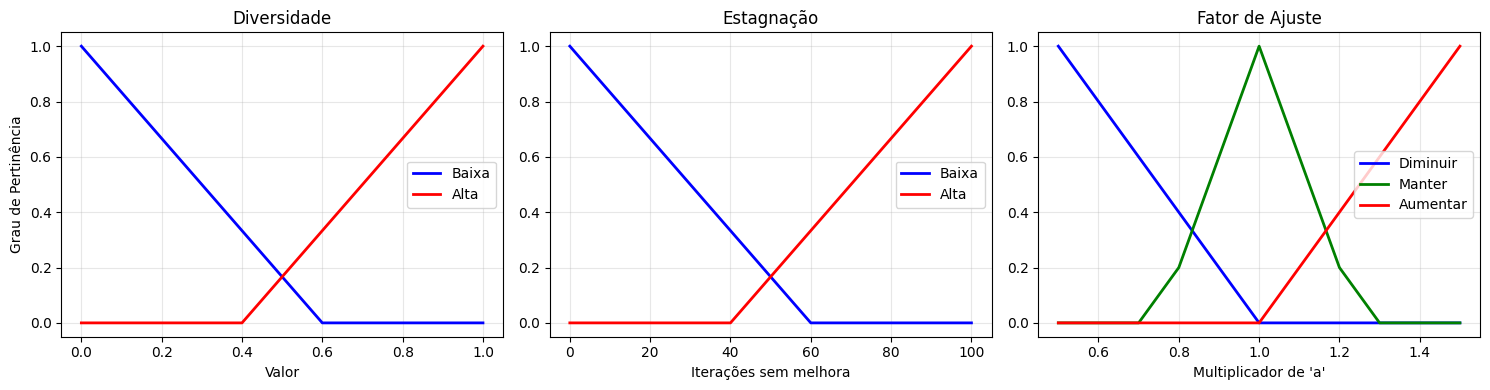

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import matplotlib.pyplot as plt

# ==========================================
# Gráfico 2 (CORRIGIDO): Funções de Pertinência
# ==========================================
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4))

# 1. Diversidade
ax1.plot(div.universe, div['baixa'].mf, 'b', linewidth=2, label='Baixa')
ax1.plot(div.universe, div['alta'].mf, 'r', linewidth=2, label='Alta')
ax1.set_title("Diversidade")
ax1.set_ylabel("Grau de Pertinência")
ax1.set_xlabel("Valor")
ax1.legend()
ax1.grid(True, alpha=0.3)

# 2. Estagnação
ax2.plot(est.universe, est['baixa'].mf, 'b', linewidth=2, label='Baixa')
ax2.plot(est.universe, est['alta'].mf, 'r', linewidth=2, label='Alta')
ax2.set_title("Estagnação")
ax2.set_xlabel("Iterações sem melhora")
ax2.legend()
ax2.grid(True, alpha=0.3)

# 3. Fator de Ajuste
ax3.plot(ajuste.universe, ajuste['diminuir'].mf, 'b', linewidth=2, label='Diminuir')
ax3.plot(ajuste.universe, ajuste['manter'].mf, 'g', linewidth=2, label='Manter')
ax3.plot(ajuste.universe, ajuste['aumentar'].mf, 'r', linewidth=2, label='Aumentar')
ax3.set_title("Fator de Ajuste")
ax3.set_xlabel("Multiplicador de 'a'")
ax3.legend()
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("fuzzy_funcoes_pertinencia.png", dpi=150)
plt.show()

from google.colab import files
files.download("fuzzy_funcoes_pertinencia.png")

In [ ]:
# ============================================================
# GERADOR DA PLANILHA MESTRE (Semanas 3, 4 e 5)
# ============================================================
import pandas as pd
import os
from google.colab import files

print(">>> Construindo Planilha Mestre com todos os dados do projeto...")

# 1. Dados Brutos das 4 versões (Semana 4/5)
df_brutos_4v = df_s6.copy()
# Adicionando a coluna de Porte
df_brutos_4v["Porte"] = "Small"

# 2. Tabela Resumo das 4 versões (O que vai no relatório)
df_resumo_4v = df_brutos_4v.groupby("Versao").agg(
    Media=("Fitness", "mean"),
    Mediana=("Fitness", "median"),
    Desvio=("Fitness", "std"),
    Tempo_Medio_s=("Tempo_s", "mean"),
    Avaliacoes=("Avaliacoes", "first")
).round(4).reset_index()

# 3. Dados do Surrogate (Semana 4)
# Se a variável não existir na memória, tenta ler o CSV
try:
    df_surr = df_surrogate.copy()
except NameError:
    df_surr = pd.read_csv("resultados_surrogate.csv")

# 4. Dados do Fuzzy (Semana 5)
try:
    df_fuzz = df_fuzzy.copy()
except NameError:
    df_fuzz = pd.read_csv("historico_fuzzy.csv")

# 5. Construção da Legenda Mestre
legenda = [
    # Aba 1
    ("1_Dados_Brutos_4Versoes", "Versao", "Algoritmo avaliado (Baseline, Tunado, Surrogate, Fuzzy)"),
    ("1_Dados_Brutos_4Versoes", "Seed", "Semente aleatória da execução (0 a 29)"),
    ("1_Dados_Brutos_4Versoes", "Fitness", "Tardiness obtido (menor é melhor)"),
    ("1_Dados_Brutos_4Versoes", "Tempo_s", "Tempo de execução em segundos"),
    ("1_Dados_Brutos_4Versoes", "Avaliacoes", "Número de chamadas da função objetivo"),
    # Aba 2
    ("2_Resumo_4Versoes", "Media", "Média do Tardiness"),
    ("2_Resumo_4Versoes", "Mediana", "Mediana do Tardiness"),
    ("2_Resumo_4Versoes", "Desvio", "Desvio padrão"),
    ("2_Resumo_4Versoes", "Tempo_Medio_s", "Tempo médio de execução"),
    # Aba 3
    ("3_Metricas_Surrogate", "MSE", "Erro Quadrático Médio da Rede Neural"),
    ("3_Metricas_Surrogate", "RMSE", "Raiz do Erro Quadrático Médio"),
    ("3_Metricas_Surrogate", "R2", "Coeficiente de Determinação (qualidade do ajuste)"),
    ("3_Metricas_Surrogate", "Ganho_Tempo_x", "Quantas vezes o Surrogate foi mais rápido que o real"),
    # Aba 4
    ("4_Historico_Fuzzy", "Iteracao", "Geração do GWO"),
    ("4_Historico_Fuzzy", "Fator_Ajuste", "Multiplicador aplicado ao parâmetro 'a'"),
    ("4_Historico_Fuzzy", "Valor_a", "Valor final do parâmetro 'a' na geração"),
]
df_legenda = pd.DataFrame(legenda, columns=["Aba", "Coluna", "Descricao"])

# 6. Salvando o arquivo Excel
arquivo_mestre = "Master_Relatorio_Semanas_3_4_5.xlsx"
with pd.ExcelWriter(arquivo_mestre, engine='openpyxl') as writer:
    df_legenda.to_excel(writer, sheet_name="0_Legenda", index=False)
    df_brutos_4v.to_excel(writer, sheet_name="1_Dados_Brutos_4Versoes", index=False)
    df_resumo_4v.to_excel(writer, sheet_name="2_Resumo_4Versoes", index=False)
    df_surr.to_excel(writer, sheet_name="3_Metricas_Surrogate", index=False)
    df_fuzz.to_excel(writer, sheet_name="4_Historico_Fuzzy", index=False)

print(f"✅ Planilha Mestre gerada: {arquivo_mestre} (5 abas)")
files.download(arquivo_mestre)

# Exibe a tabela resumo na tela para você copiar no LaTeX
print("\n--- Tabela Resumo para o Relatório ---")
print(df_resumo_4v.to_string(index=False))

# Exibe as métricas do Surrogate
print("\n--- Métricas do Surrogate ---")
print(df_surr.to_string(index=False))

>>> Construindo Planilha Mestre com todos os dados do projeto...
✅ Planilha Mestre gerada: Master_Relatorio_Semanas_3_4_5.xlsx (5 abas)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


--- Tabela Resumo para o Relatório ---
   Versao   Media  Mediana  Desvio  Tempo_Medio_s  Avaliacoes
 Baseline 306.000 306.0000  0.0000         0.6504        3000
    Fuzzy 306.000 306.0000  0.0000         1.1422        3000
Surrogate 268.492 269.9778  2.0308         1.1894        3000
   Tunado 306.000 306.0000  0.0000         0.6650        5500

--- Métricas do Surrogate ---
    Instancia  N_Amostras_LHS        MSE      RMSE       R2  Tempo_Real_s  Tempo_Surrogate_s  Ganho_Tempo_x  Fitness_Real  Fitness_Surrogate
I_3_4_2_3.txt             500 605.143714 24.599669 0.879137      0.218026           1.317008       0.165547         306.0         265.955256


In [ ]:
# Rode para extrair o ganho real na instância Large
import time
from scipy.stats import qmc
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
import numpy as np

inst_large = GERAL[0]
n_l, m_l, p_l, d_l = FlowShopEngine.carregar_instancia_txt(inst_large)
engine_l = FlowShopEngine(n_l, m_l, p_l, d_l)

# Treino rápido
N = 150
sampler = qmc.LatinHypercube(d=n_l, seed=42)
X_l = sampler.random(n=N)
y_l = np.array([engine_l.evaluate(x) for x in X_l]).reshape(-1, 1)
scaler = StandardScaler()
mlp_l = MLPRegressor(hidden_layer_sizes=(64, 64), max_iter=300)
mlp_l.fit(X_l, scaler.fit_transform(y_l).ravel())

# Medindo 100 avaliações
x_teste = X_l[0].reshape(1, -1)
t0 = time.time(); [engine_l.evaluate(x_teste[0]) for _ in range(100)]; t_real = time.time() - t0
t0 = time.time(); [mlp_l.predict(x_teste) for _ in range(100)]; t_surr = time.time() - t0

print(f"Ganho de velocidade na LARGE: {t_real / t_surr:.2f}x mais rápido")

Ganho de velocidade na LARGE: 1.90x mais rápido


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import os
from google.colab import files

print("Gerando as 4 imagens exatas para o Overleaf...")

# ==========================================
# 1. Surrogate - Curva de Aprendizado
# ==========================================
plt.figure(figsize=(8, 4))
plt.plot(mlp.loss_curve_, color='red', linewidth=2)
plt.title("Curva de Aprendizado da Rede Neural (Surrogate)")
plt.xlabel("Época (Iteração de Treino)")
plt.ylabel("Loss (Erro)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("surrogate_curva_aprendizado.png", dpi=150)
plt.close()

# ==========================================
# 2. Surrogate - Gráfico de Paridade
# ==========================================
# Recalculando as predições para garantir que os dados estão certos
y_pred_scaled = mlp.predict(X_test)
y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).flatten()
y_test_real = y_test.flatten()

plt.figure(figsize=(6, 6))
plt.scatter(y_test_real, y_pred, alpha=0.6, color='teal', edgecolors='k')
plt.plot([y_test_real.min(), y_test_real.max()], [y_test_real.min(), y_test_real.max()], 'r--', lw=2, label='Ideal (x=y)')
plt.title("Surrogate: Tardiness Real vs Predito")
plt.xlabel("Tardiness Real (FlowShopEngine)")
plt.ylabel("Tardiness Predito (MLP)")
plt.legend()
plt.tight_layout()
plt.savefig("surrogate_paridade.png", dpi=150)
plt.close()

# ==========================================
# 3. Fuzzy - Funções de Pertinência
# ==========================================
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4))

# Diversidade
ax1.plot(div.universe, div['baixa'].mf, 'b', linewidth=2, label='Baixa')
ax1.plot(div.universe, div['alta'].mf, 'r', linewidth=2, label='Alta')
ax1.set_title("Diversidade")
ax1.set_ylabel("Grau de Pertinência")
ax1.set_xlabel("Valor")
ax1.legend()
ax1.grid(True, alpha=0.3)

# Estagnação
ax2.plot(est.universe, est['baixa'].mf, 'b', linewidth=2, label='Baixa')
ax2.plot(est.universe, est['alta'].mf, 'r', linewidth=2, label='Alta')
ax2.set_title("Estagnação")
ax2.set_xlabel("Iterações sem melhora")
ax2.legend()
ax2.grid(True, alpha=0.3)

# Fator de Ajuste
ax3.plot(ajuste.universe, ajuste['diminuir'].mf, 'b', linewidth=2, label='Diminuir')
ax3.plot(ajuste.universe, ajuste['manter'].mf, 'g', linewidth=2, label='Manter')
ax3.plot(ajuste.universe, ajuste['aumentar'].mf, 'r', linewidth=2, label='Aumentar')
ax3.set_title("Fator de Ajuste")
ax3.set_xlabel("Multiplicador de 'a'")
ax3.legend()
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("fuzzy_funcoes_pertinencia.png", dpi=150)
plt.close()

# ==========================================
# 4. Fuzzy - Evolução do Parâmetro 'a'
# ==========================================
# Usando os dados do DataFrame df_fuzzy que geramos
iteracoes = df_fuzzy['Iteracao'].values
valor_a = df_fuzzy['Valor_a'].values

plt.figure(figsize=(10, 4))
plt.plot(iteracoes, valor_a, color='darkorange', linewidth=2, label='a (Fuzzy)')
a_linear = [2.0 - 2.0 * (t / len(iteracoes)) for t in iteracoes]
plt.plot(iteracoes, a_linear, 'k--', alpha=0.5, label='a (Linear Padrão)')
plt.title("Evolução do Parâmetro 'a' ao Longo das Gerações")
plt.xlabel("Iteração")
plt.ylabel("Valor de 'a'")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("fuzzy_evolucao_parametro.png", dpi=150)
plt.close()

print("✅ Todas as 4 imagens foram geradas com os nomes corretos!")
print("Iniciando download...")

# Download automático
imagens = [
    "surrogate_paridade.png",
    "surrogate_curva_aprendizado.png",
    "fuzzy_funcoes_pertinencia.png",
    "fuzzy_evolucao_parametro.png"
]

for img in imagens:
    if os.path.exists(img):
        files.download(img)
        print(f"[OK] Baixado: {img}")
    else:
        print(f"[ERRO] Falha ao gerar: {img}")

Gerando as 4 imagens exatas para o Overleaf...
✅ Todas as 4 imagens foram geradas com os nomes corretos!
Iniciando download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

[OK] Baixado: surrogate_paridade.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (3 outputs left out)

[OK] Baixado: fuzzy_funcoes_pertinencia.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

[OK] Baixado: fuzzy_evolucao_parametro.png
